# Example 4: a ball with a random center

A ball with fixed radius $r=2$ whose center is uniformly distributed in $[-1, 1]^2$. The notebook shows its quantile sets $K_\alpha$ (in 2D and 3D), the pairplot between the level $\alpha$, the containment probability and the volume of $K_\alpha$, and the symmetry plot.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from Polytope import Polytope
from PolytopeRandomSet import PolytopeRandomSet
from utils import ANGLES, set_plotting_style, save_figure

set_plotting_style()

SAVE_FIGURES = False   # set to True to export the figures used in the paper (folder /images must exist)

### 1. Sample
Each realization is a ball of radius $r$ with a random center, approximated by a polygon with 360 vertices (one per angle in `ANGLES`). The sample has 10,000 realizations.

In [3]:
rng = np.random.default_rng(2026)

def random_ball(r):
    """A ball of radius r with center uniform on [-1, 1]^2, as a 360-gon."""
    center = rng.uniform(-1, 1, 2)
    vertices = [center + np.array([r*np.cos(a), r*np.sin(a)]) for a in ANGLES]
    return Polytope(V=np.array(vertices))

RS = PolytopeRandomSet([random_ball(r=2) for _ in range(10_000)])

### 2. Quantile sets $K_\alpha$
Quantiles for 21 equally spaced levels $\alpha \in [0, 1]$, colored by $\alpha$.

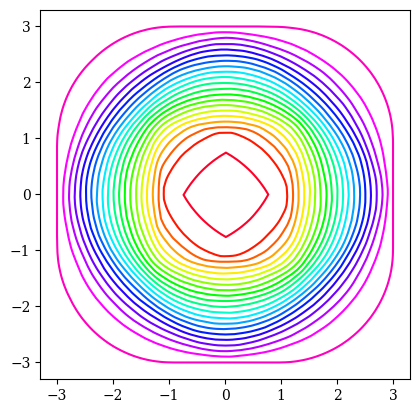

In [4]:
RS.plot_quantiles(alphas=np.linspace(0, 1, 21))
if SAVE_FIGURES:
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    save_figure(plt.gcf(), "images/rand_ball_contours", fig_size=(4, 4))
plt.show()

The same quantiles in 3D, each placed at the height $\alpha$ (41 levels).

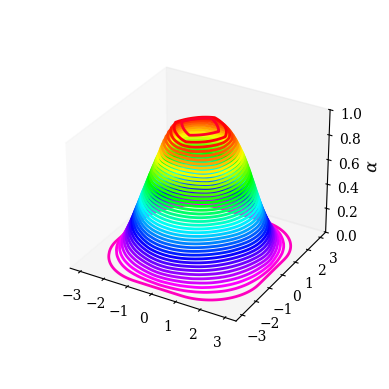

In [5]:
RS.plot_quantiles_3d(alphas=np.linspace(0, 1, 41))
if SAVE_FIGURES: save_figure(plt.gcf(), "images/rand_ball_contours_3d", fig_size=(5, 5))
plt.show()

### 3. Pairplot between $\alpha$, containment probability $\mathsf P(X \subseteq K_\alpha)$ and the volume of $K_\alpha$

*Warning:* computation can take a while.

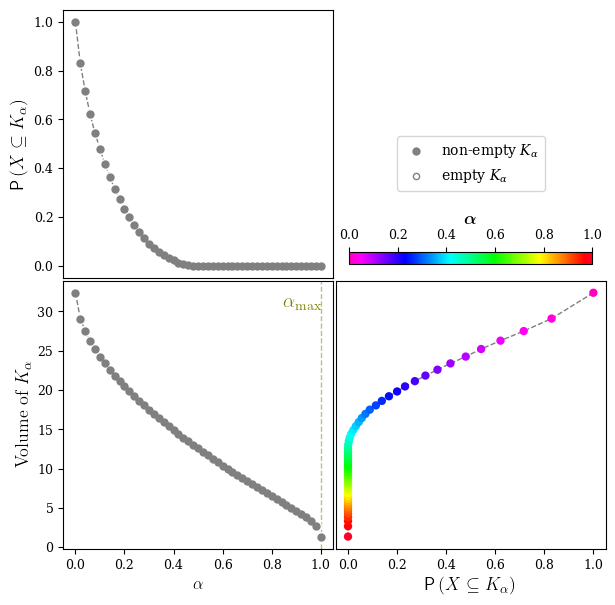

In [5]:
RS.pairplot()
plt.show()

### 4. Symmetry plot

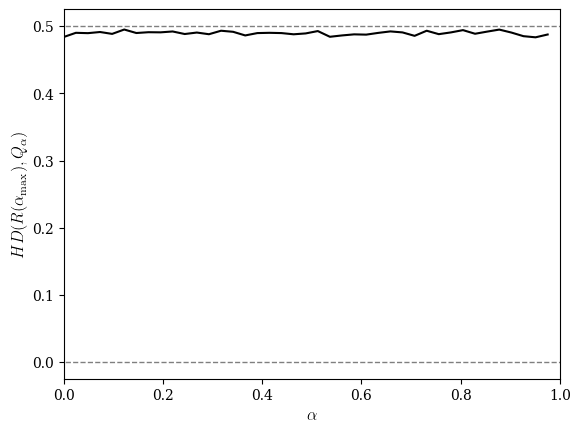

In [6]:
RS.symmetry_plot(seed=2026)
if SAVE_FIGURES: save_figure(plt.gcf(), "images/rand_ball_symmetry_plot", fig_size=(4, 4))
plt.show()